# Traballo 

En base ás outras columnas predecir os valores de anx e de dep. Análise de regresión con sklearn e rede neuronal con tensorflow, empregamos seaborn para representación de datos

## 1. Depuración de datos

In [257]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import sys
import os
# sys.path.append(os.path.dirname(os.path.abspath(____)))
sys.path.append(os.getcwd()) # solución e ia, non entendo a diferenza

In [258]:
# df = pd.read_csv('Student_Depression_Dataset.csv') # https://www.kaggle.com/datasets/mkhoirulmustaqim/student-depression-detection-dataset/data
df = pd.read_csv('anxiety_depression_data.csv') # vou usar este me parece https://www.kaggle.com/datasets/ak0212/anxiety-and-depression-mental-health-factors/data
df.head()

# outro interesante é https://www.kaggle.com/datasets/beamhonor0911/digital-insomnia-screen-habits-sleep

,Age,Gender,Education_Level,Employment_Status,Sleep_Hours,Physical_Activity_Hrs,Social_Support_Score,Anxiety_Score,Depression_Score,Stress_Level,...,Chronic_Illnesses,Medication_Use,Therapy,Meditation,Substance_Use,Financial_Stress,Work_Stress,Self_Esteem_Score,Life_Satisfaction_Score,Loneliness_Score
0,56,Male,Bachelor's,Unemployed,6.0,0.4,3,4,2,9,...,0,NaN,0,1,NaN,4,3,7,5,1
1,69,Female,Bachelor's,Retired,8.8,2.8,6,18,7,6,...,0,NaN,1,0,NaN,1,4,7,4,6
2,46,Female,Master's,Employed,5.3,1.6,5,5,13,8,...,0,NaN,0,1,NaN,8,7,8,1,1
3,32,Female,High School,Unemployed,8.8,0.5,4,6,3,4,...,1,NaN,0,0,NaN,7,4,8,4,4
4,60,Female,Bachelor's,Retired,7.2,0.7,2,7,15,3,...,0,NaN,1,1,Frequent,8,9,5,7,7


In [259]:
df.info() # sinala automaticamente onde hai valores nulos e o tipo de columna

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            1200 non-null   int64  
 1   Gender                         1200 non-null   str    
 2   Education_Level                1200 non-null   str    
 3   Employment_Status              1200 non-null   str    
 4   Sleep_Hours                    1200 non-null   float64
 5   Physical_Activity_Hrs          1200 non-null   float64
 6   Social_Support_Score           1200 non-null   int64  
 7   Anxiety_Score                  1200 non-null   int64  
 8   Depression_Score               1200 non-null   int64  
 9   Stress_Level                   1200 non-null   int64  
 10  Family_History_Mental_Illness  1200 non-null   int64  
 11  Chronic_Illnesses              1200 non-null   int64  
 12  Medication_Use                 453 non-null    str    
 13 

In [260]:
# agora vemos datos máis pormenorizadamente, e.g., para Gender, podemos ver calquera dascolumnas que nos devolve df.info()
print(f"{'Gender'}: {df['Gender'].describe()}")

Gender: count       1200
unique         4
top       Female
freq         569
Name: Gender, dtype: object


Vemos que temos dúas columnas (Medication_Use e Substance_Use) que teñen celas baleiras e as columnas 'Gender', 'Education_Level', 'Employment_Status' e as xa mencionadas son strings. Esos datos teremos que depuralos

In [261]:
for i in range(len(df.columns)):
    if df[df.columns[i]].dtypes == 'str':
        print(f'Na columna <<{df.columns[i]}>> pódense tomar os seguintes valores {df[df.columns[i]].unique()}')

s = 0
for i in range(len(df)):
    if df['Education_Level'].iloc[i] == 'Other':
        s += 1
print(s)

Na columna <<Gender>> pódense tomar os seguintes valores <StringArray>
['Male', 'Female', 'Non-Binary', 'Other']
Length: 4, dtype: str
Na columna <<Education_Level>> pódense tomar os seguintes valores <StringArray>
['Bachelor's', 'Master's', 'High School', 'Other', 'PhD']
Length: 5, dtype: str
Na columna <<Employment_Status>> pódense tomar os seguintes valores <StringArray>
['Unemployed', 'Retired', 'Employed', 'Student']
Length: 4, dtype: str
Na columna <<Medication_Use>> pódense tomar os seguintes valores <StringArray>
[nan, 'Occasional', 'Regular']
Length: 3, dtype: str
Na columna <<Substance_Use>> pódense tomar os seguintes valores <StringArray>
[nan, 'Frequent', 'Occasional']
Length: 3, dtype: str
240


Segundo os valores que vemos, as variables Medication_Use e Substance_Use pódense poñer perfectamente como datos numéricos. Para os casos Gender, Education_Level e Employment_Status o mellor é traballar con variables dummies. Ademais decatémonos que o data ten xa variables booleanas (0 = False e 1 = True) nas columnas de 'Family_History_Mental_Illness', 'Chronic_Illnesses', 'Therapy' e 'Meditation'.

In [262]:
# df['Gender'] = df['Gender'].astype('category').cat.codes
Gender_dummies = pd.get_dummies(df['Gender'], prefix='Gender', dtype=int)

# df['Employment_Status'] = df['Employment_Status'].astype('category').cat.codes
Employment_Status_dummies = pd.get_dummies(df['Employment_Status'], prefix='Employment_Status', dtype=int)

# df['Education_Level'] = df['Education_Level'].astype('category').cat.codes
Education_Level_dummies = pd.get_dummies(df['Education_Level'], prefix='Education_Level', dtype=int)

# no DSM-5 sinálase que os valores de frecuencia por consumo de substancias (estupefacentes e medicación) por semana en media son como se 
# segue no diccionario: Ocasionalmente (1-2 veces por semana) = 1.5, Frecuentemente (3-5 veces por semana) = 4, Regularmente (7 veces por semana) = 7

Medication_Values = {'Occasional':2, 'Regular':7}
df['Medication_Use'] = df['Medication_Use'].map(Medication_Values)
df['Medication_Use'] = df['Medication_Use'].fillna(0)

Substance_Values = {'Occasional':2, 'Frequent':4}
df['Substance_Use'] = df['Substance_Use'].map(Substance_Values)
df['Substance_Use'] = df['Substance_Use'].fillna(0)

df = df.rename(columns={'Substance_Use': 'Substance_Use_per_week', 'Medication_Use': 'Medication_Use_per_week'})

# como na sección seguinte aínda nos vai interesar utilizar o noso dataframe df con algunhas variables str utilizamos unha copia para cando
# sexa necesario empregar os dummies que será nos puntos 3 e 4
Df = df.copy()
Df = pd.concat([Df.drop(columns=['Gender','Employment_Status','Education_Level']),
                                Gender_dummies, Education_Level_dummies, Employment_Status_dummies],
                                axis=1)

Df.head()

,Age,Sleep_Hours,Physical_Activity_Hrs,Social_Support_Score,Anxiety_Score,Depression_Score,Stress_Level,Family_History_Mental_Illness,Chronic_Illnesses,Medication_Use_per_week,...,Gender_Other,Education_Level_Bachelor's,Education_Level_High School,Education_Level_Master's,Education_Level_Other,Education_Level_PhD,Employment_Status_Employed,Employment_Status_Retired,Employment_Status_Student,Employment_Status_Unemployed
0,56,6.0,0.4,3,4,2,9,0,0,0.0,...,0,1,0,0,0,0,0,0,0,1
1,69,8.8,2.8,6,18,7,6,0,0,0.0,...,0,1,0,0,0,0,0,1,0,0
2,46,5.3,1.6,5,5,13,8,0,0,0.0,...,0,0,0,1,0,0,1,0,0,0
3,32,8.8,0.5,4,6,3,4,1,1,0.0,...,0,0,1,0,0,0,0,0,0,1
4,60,7.2,0.7,2,7,15,3,0,0,0.0,...,0,1,0,0,0,0,0,1,0,0


In [263]:
if df.duplicated().sum() > 0:
    print(f'Hai {df.duplicated().sum()} filas duplicadas (dexeneración de datos) no DataFrame. Logo temos que depurar estos datos duplicados, e.g. eliminándoos')
else:
    print('Non hai filas duplicadas. Nada que facer.')

Non hai filas duplicadas. Nada que facer.


## 2. Representacións estatísticas

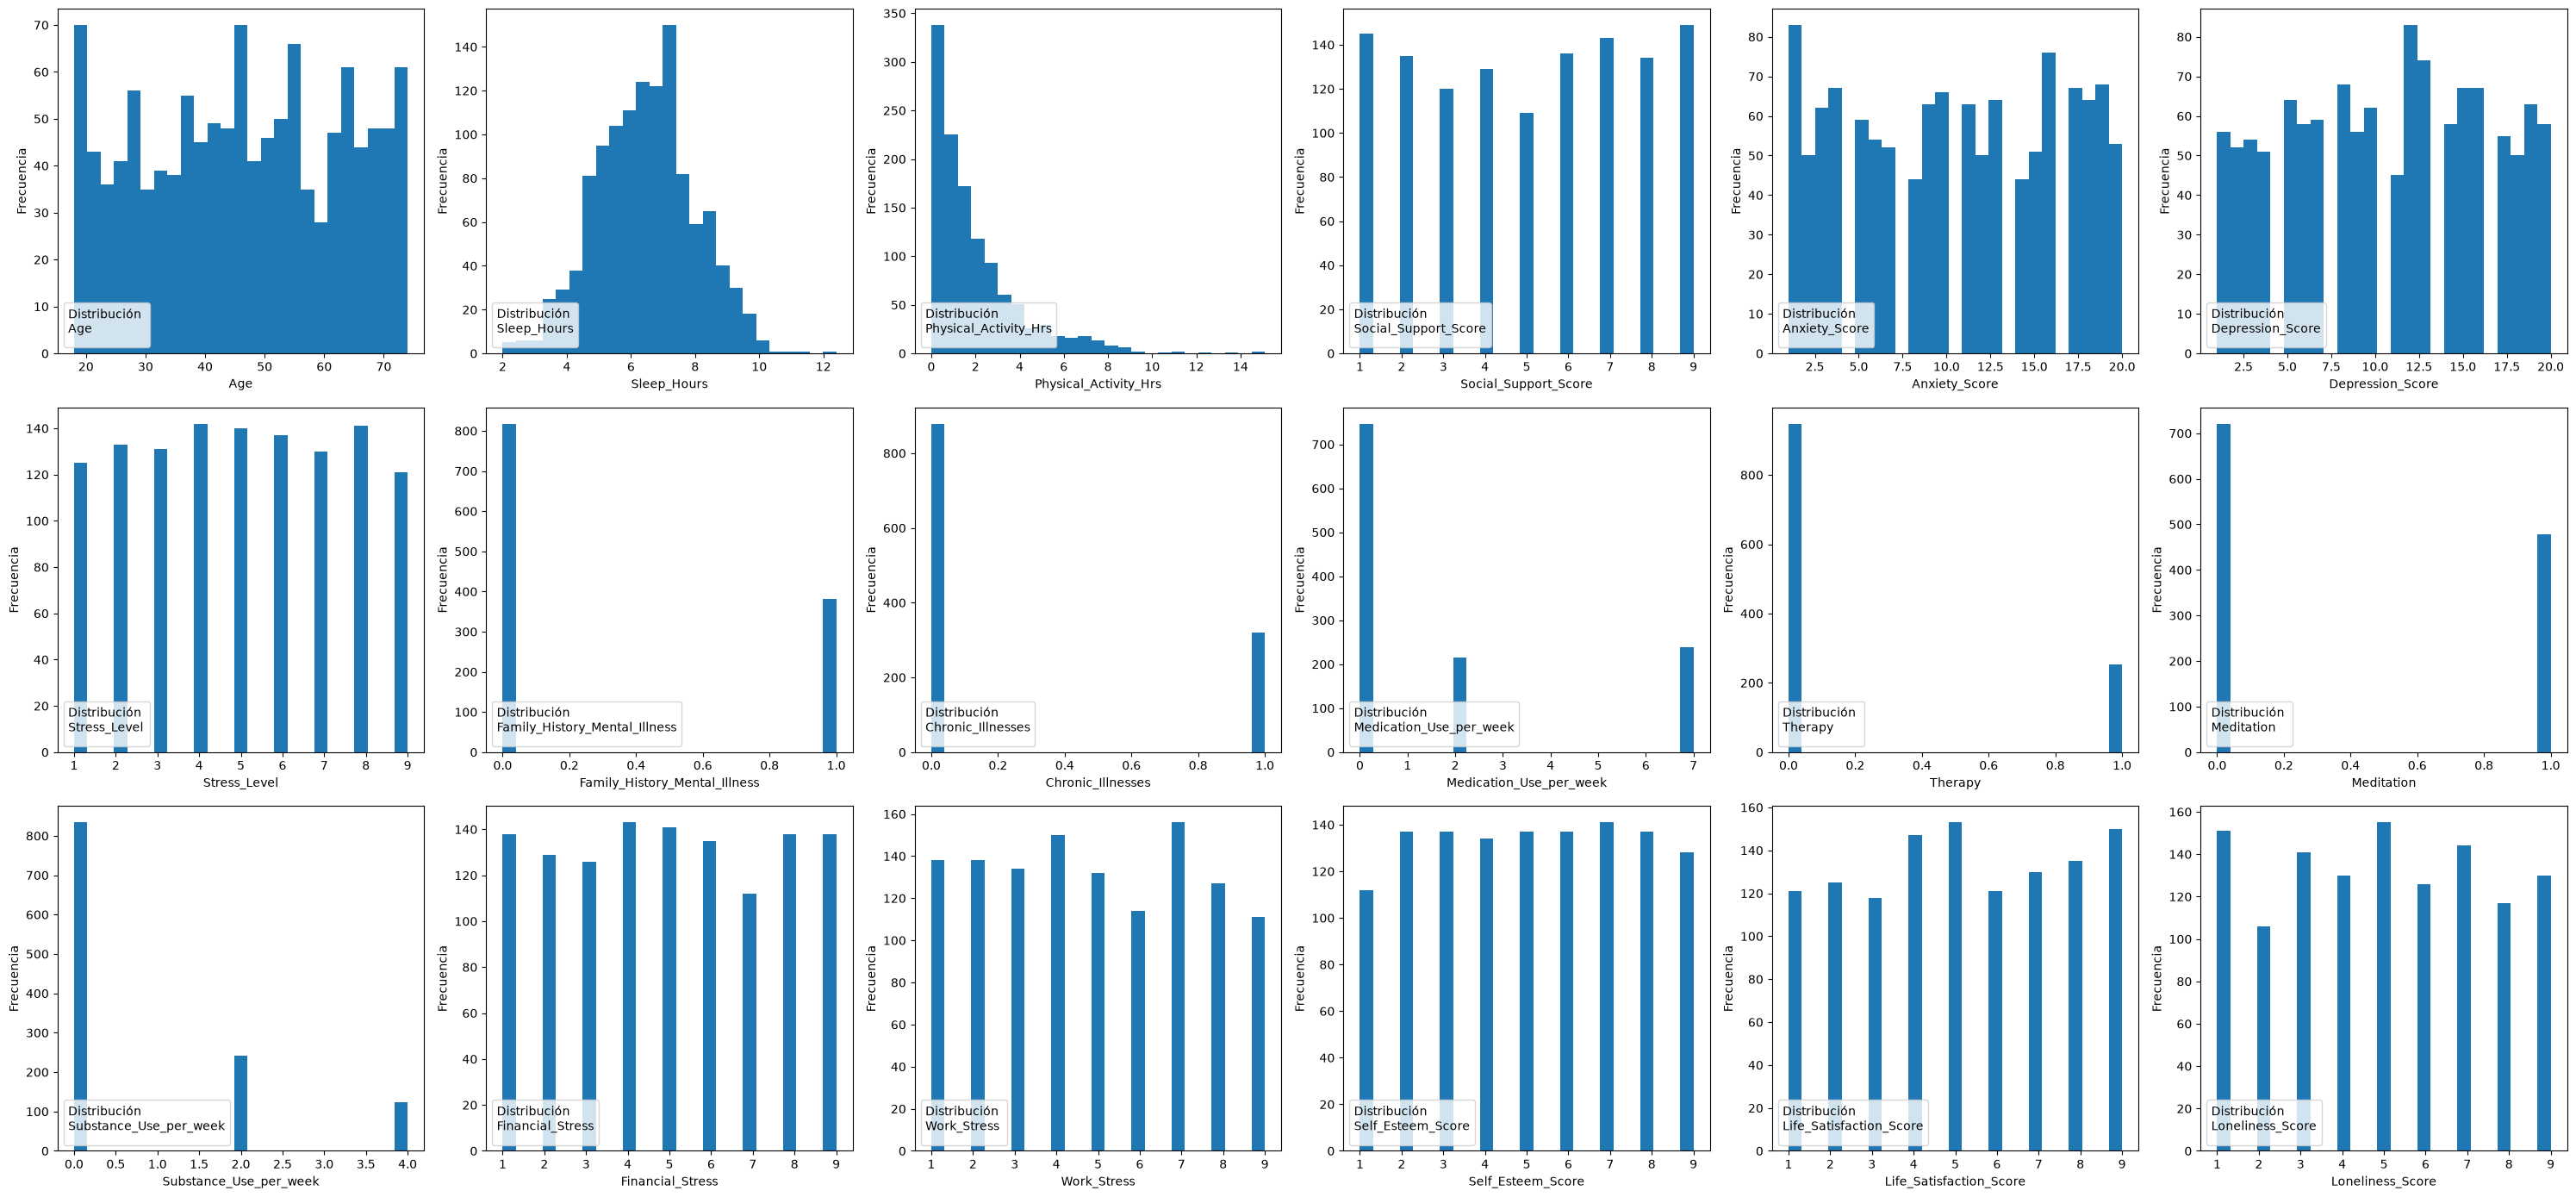

In [264]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
fig, axs = plt.subplots(3,6, figsize=(30, 14))

num_vert = 0; num_hor = 0
for cols in numeric_cols: # lembremos que hai 4 columnas que son booleanas, polo que falar de distribución de frecuencia non ten moito sentido, pero para as outras 14 columnas si que o ten sentido
    
    axs[num_vert,num_hor].hist(df[cols], bins=25)
    axs[num_vert,num_hor].legend( title=f'Distribución \n{cols}', loc='lower left')
    axs[num_vert,num_hor].axes.get_xaxis().set_visible(True)
    axs[num_vert,num_hor].axes.get_yaxis().set_visible(True)
    axs[num_vert,num_hor].set_xlabel(f'{cols}')
    axs[num_vert,num_hor].set_ylabel('Frecuencia')
    
    num_hor += 1
    if num_vert == 0 and num_hor == 6:
            num_vert = 1
            num_hor = 0

    elif num_vert == 1 and num_hor == 6:
            num_vert = 2
            num_hor = 0    
        
plt.tight_layout()
fig.show()

En xeral pode dicirse que todas aquelas variables que se podan aproximar a unha distribución estatística son de tipo cadrada. As variables <<Sleep_Hours>> e <<Depression_Score>> son máis ou menos unha gaussiana (talvez as horas de sono sexa máis unha Poisson) e a distribución de <<Physical_Activity_Hours>> é unha exponencial. Datos relevantes son a moda e a media

In [265]:
# quero dar a moda e media de 3 distrbucións
distrib = ('Sleep_Hours', 'Depression_Score', 'Physical_Activity_Hrs')
for cat in distrib:
    print(f'En {cat} a media é {df[cat].mean():.2f} e a moda é {df[cat].mode().tolist()}')

En Sleep_Hours a media é 6.47 e a moda é [6.8]
En Depression_Score a media é 10.67 e a moda é [12]
En Physical_Activity_Hrs a media é 2.01 e a moda é [0.1]


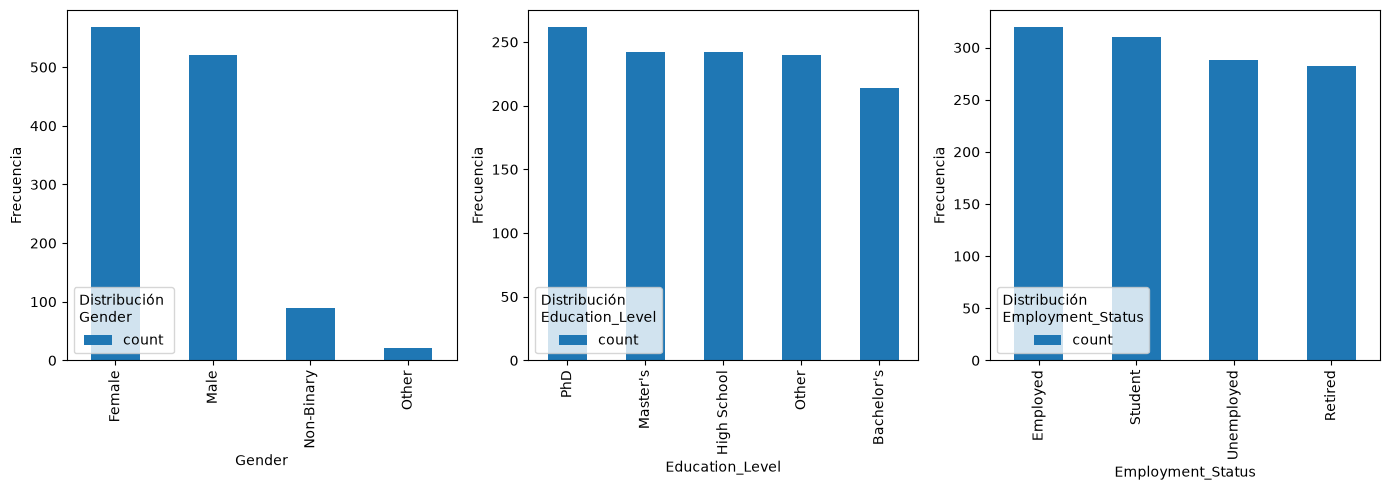

In [266]:
df = pd.read_csv('anxiety_depression_data.csv') # vou usar este me parece https://www.kaggle.com/datasets/ak0212/anxiety-and-depression-mental-health-factors/data

categorical_cols = df.select_dtypes(include=['object']).columns

fig, axs = plt.subplots(1,3, figsize=(14, 5))

num_hor = 0
for col in categorical_cols[:3]:
    df[col].value_counts().plot(kind='bar', ax=axs[num_hor])
    axs[num_hor].legend(title=f'Distribución \n{col}', loc='lower left')
    axs[num_hor].set_xlabel(col)
    axs[num_hor].set_ylabel('Frecuencia')
    num_hor += 1
        
plt.tight_layout()
fig.show()

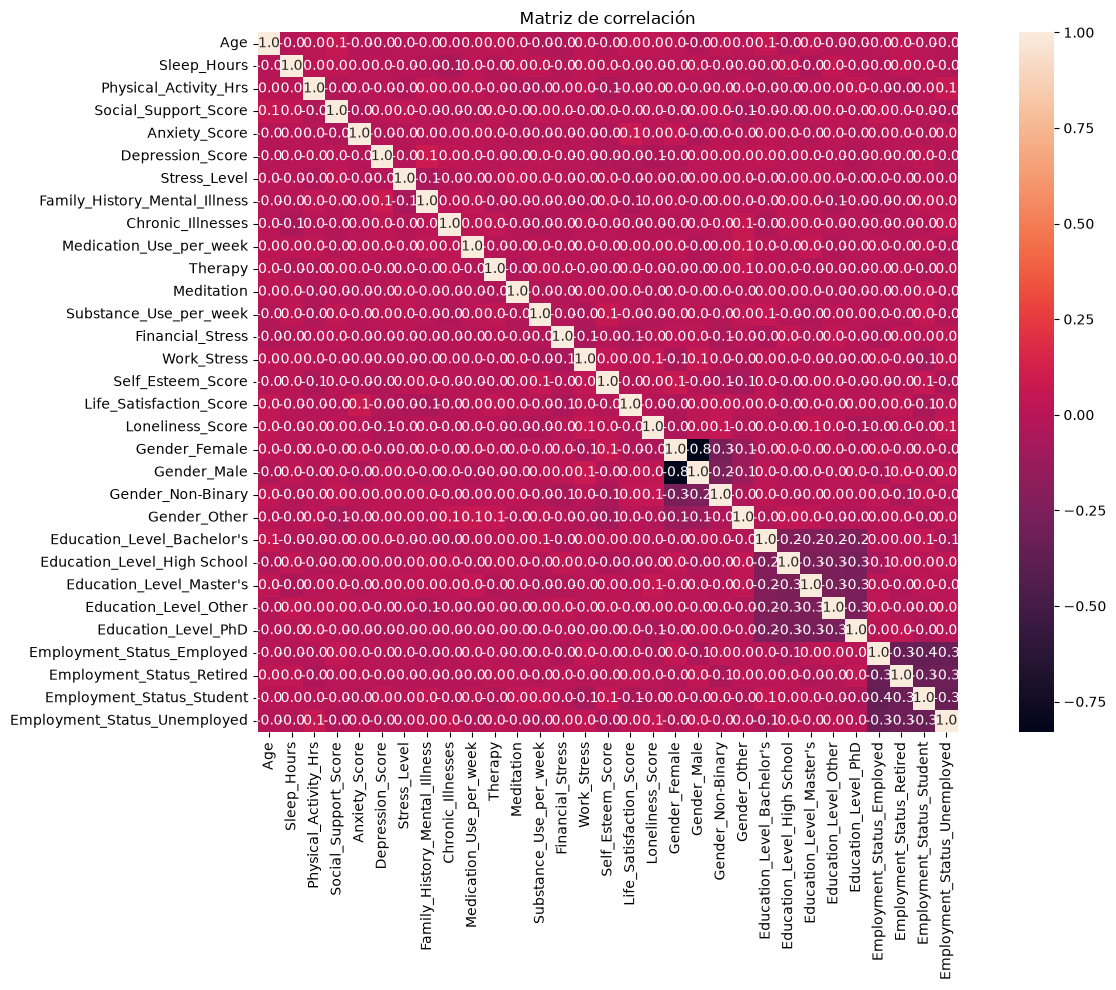

In [267]:
# Aquí empregamos o DataFrame Df, onde eliminamos as columnas categóricas e integramos os dummies correspondentes a cada 
# unha delas; é necesario para facer unha correlación numéricas.

# mapa de calor
plt.figure(figsize=(14, 10))
sns.heatmap(Df.corr(), annot=True, fmt='.1f', square=True#, cmap='coolwarm'
            )
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()


Vemos que na diagonal aparecen 3 cadradados pequenos de correlación negativa moi significativa, isto derívase de que son as submatrices das variables dummies que son autoexcluíntes. Obviamente non pode haber un desempregado e empregado á vez.

In [268]:
# Let's break down Depression_Score into categories
# Example ranges: 0-6 (Low), 7-13 (Medium), 14+ (High) — common classification

def categorize_Scores(score): # Depression e Anxiety chegan até 20, equiespaciadamente temos:
    # aínda que se podería coller a partición con só 3 categorías, como no caso de Loneliness
    if score <= 5:
        return 'Low'
    elif score <= 8:
        return 'Medium-Low'
    elif score <= 12:
            return 'Medium'
    elif score <= 16:
            return 'Medium-High'
    else:
        return 'High'

def Loneliness(score): # a soidade só até 10
    if score <= 3:
        return 'Low'
    elif score <= 6:
            return 'Medium'
    else:
        return 'High'


Depression_Level = df['Depression_Score'].apply(categorize_Scores)
Anxiety_Level = df['Anxiety_Score'].apply(categorize_Scores)
Loneliness_Level = df['Loneliness_Score'].apply(Loneliness)

# Poderiamos facelo en realidade para calquera parámetro, escollemos idade e xénero por evidenciar se as mental illness están sesgados por eles 
corr_Age_Gender = pd.concat([df['Age'],df['Gender'],Depression_Level, Anxiety_Level, Loneliness_Level], axis=1)

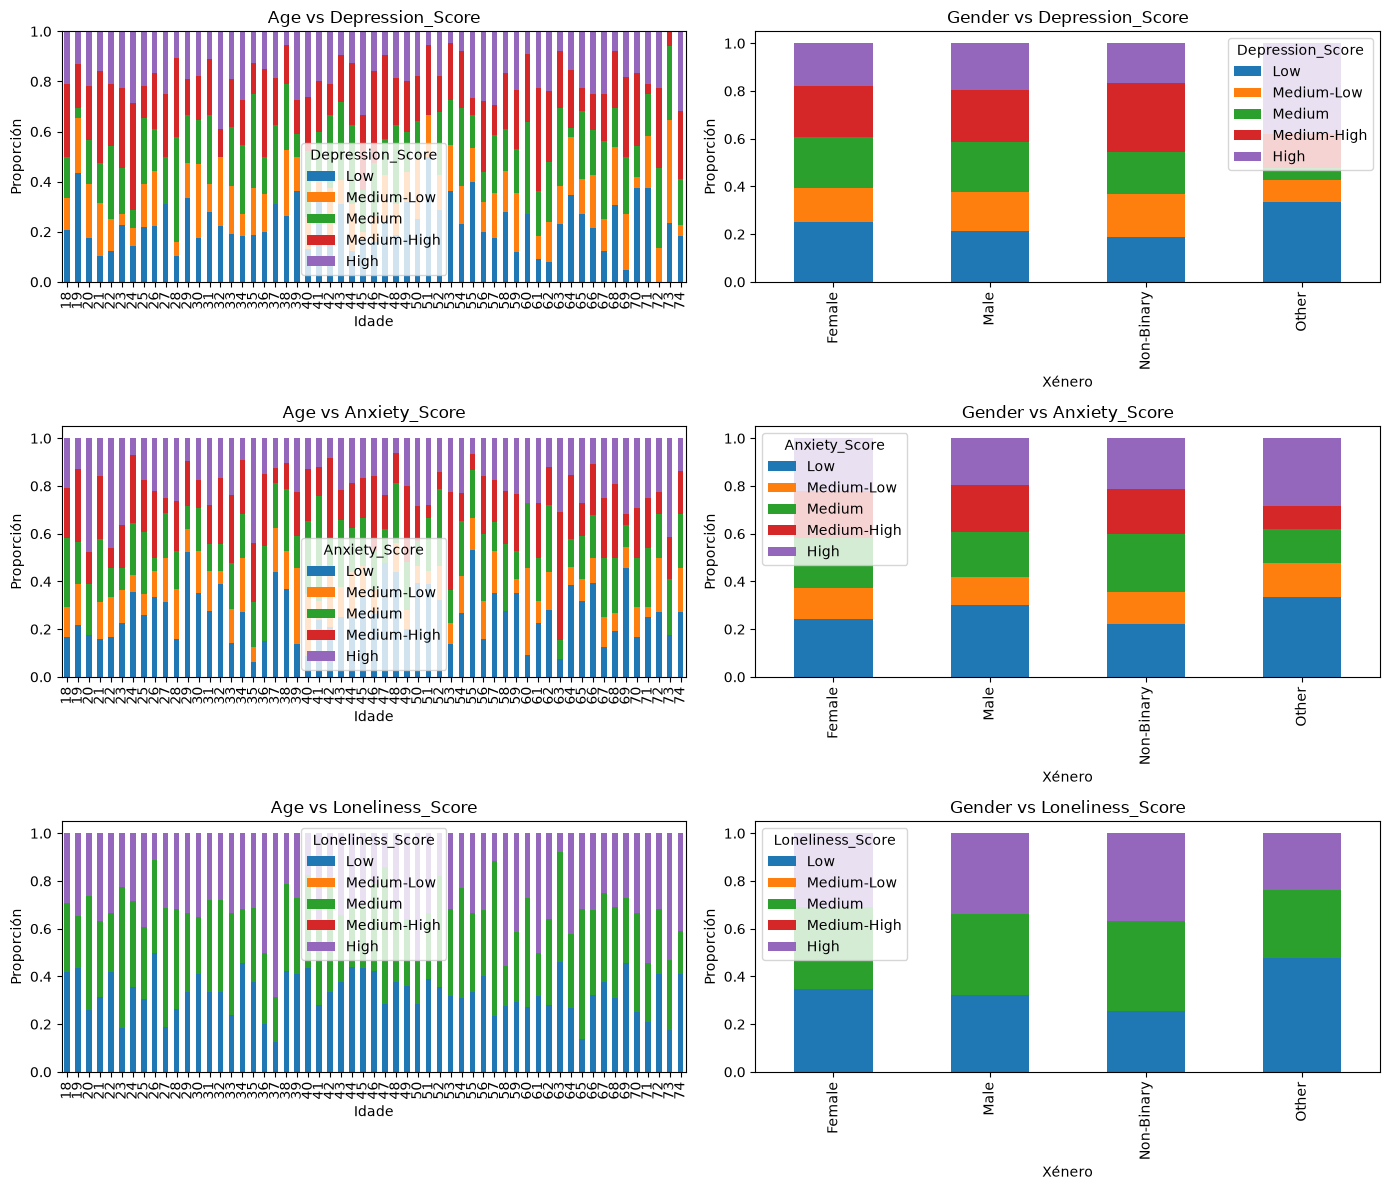

In [269]:
Scores = ('Depression_Score', 'Anxiety_Score', 'Loneliness_Score')
Rangos = ('Low', 'Medium-Low', 'Medium', 'Medium-High', 'High')

fig, axs = plt.subplots(3, 2, figsize=(14, 12))

for i, score in enumerate(Scores):
    edad_score = (corr_Age_Gender.groupby('Age')[score].value_counts(normalize=True).unstack().fillna(0))
    xenero_score = (corr_Age_Gender.groupby('Gender')[score].value_counts(normalize=True).unstack().fillna(0))

    edad_score.reindex(columns=Rangos).plot(kind='bar',stacked=True,ax=axs[i, 0])
    xenero_score.reindex(columns=Rangos).plot(kind='bar',stacked=True,ax=axs[i, 1])

    axs[i, 0].set_title(f'Age vs {score}')
    axs[i, 0].set_ylabel('Proporción')
    axs[i, 0].set_xlabel('Idade')

    axs[i, 1].set_title(f'Gender vs {score}')
    axs[i, 1].set_ylabel('Proporción')
    axs[i, 1].set_xlabel('Xénero')

plt.tight_layout()
plt.show()

Agora, previo a proceder ás dúas análises de predicción das variables <<Depression_Score>>, <<Anxiety_Score>> e <<Loneliness_Score>> debemos separar as nosas mostras de datos en datos de entrenamento e de testeo. Será necesario que utilizemos o dataframe onde substituímos as columnas str polos dummies respectivos (Df).

In [270]:
y_anx = Df.Anxiety_Score
y_dep = Df.Depression_Score
y_lon = Df.Loneliness_Score

Podemos propoñer dous tipos de análises, un onde descartamos os outros y'es para un y'dado (i.e., descartamos a dependencia de ansiedad, depresión e loneliness) o cal non creo que teña moito sentido porque no DSM-5 sinálase a soidade como factor de risco da depresión e á vez tamén que as sintomatoloxías ansiosas e depresivas están fortemente ligadas acabando por difuminarse. Así que temos que escoller uns datos X para cada Y onde no X só se descarte o propio Y.

In [271]:
X_anx = Df.drop('Anxiety_Score', axis=1)
X_dep = Df.drop('Depression_Score', axis=1)
X_lon = Df.drop('Loneliness_Score', axis=1)

In [272]:
split = round(X_anx.shape[0]*0.80) # todas as X son do mesmo tamaño, non distinguimos
X1_train, X1_test = X_anx[:split], X_anx[split:]
y1_train, y1_test = y_anx[:split], y_anx[split:]
X2_train, X2_test = X_dep[:split], X_dep[split:]
y2_train, y2_test = y_dep[:split], y_dep[split:]
X3_train, X3_test = X_lon[:split], X_lon[split:]
y3_train, y3_test = y_lon[:split], y_lon[split:]

## 3. Análise con sklearn (regresión loxística)

# 4. Análise con tensorflow (rede neuronal)

In [190]:
import tensorflow as tf

from keras import layers
from keras.models import Sequential

model = tf.keras.Sequential([
    layers.Input(shape=(116,)),
    layers.Dense(30, activation='relu'),
    layers.Dense(30, activation='relu'),
    layers.Dense(30, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])